The purpose of this project is to determine if topological data analysis (TDA) can detect features in spatiotemporal data better than other methods.

The motivation is seismic data, where one collects readings across time from many locations and wants to detect underground features.

This notebook contains code translated from Julia, used for part of the paper: https://arxiv.org/abs/2506.15020

In [36]:
import redzed_tda as rz
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy.stats import spearmanr
import networkx as nx

Topological daata analysis is used to detect topological features (holes) in data. For example, consider the dataset below:

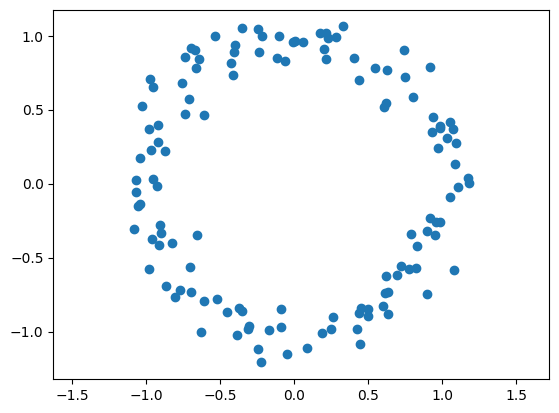

In [2]:
np.random.seed(0)

points = [
    [np.cos(x) + np.random.normal(0,0.1), np.sin(x) + np.random.normal(0,0.1)]
    for x in np.arange(0,2*np.pi, 0.05)
]

points = np.array(points)

plt.scatter(points[:,0], points[:,1])
plt.axis('equal')
plt.show()

This dataset has one (1-dimensional) hole, the circle itself, which we can detect using persistent homology:

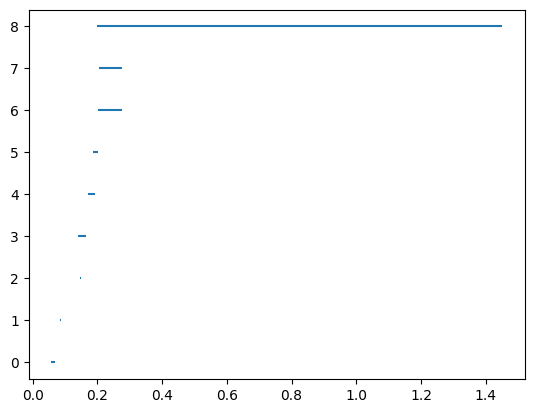

In [3]:
distance_matrix = rz.pairwise_distances(points)
H0, H1 = rz.rips(distance_matrix, 1)

plt.hlines(range(len(H1)), 
           [b for b, d in H1], 
           [d for b, d in H1])
plt.show()

The long bar corresponds to one large persistent hole. The smaller bars arise due to noise.

The first step of our analysis is to build simulated spatiotemporal data. This follows the approach in the paper. We generate a grid of points in space, and update to get a time series of readings at each point, where readings are based on surrounding points with randomness added in.

In [68]:
# define the distance between two grid points
def distance(a,b):
    return ((a[0]-b[0])**2 + (a[1]-b[1])**2)**(1/2)

# return a dictionary storing the distances for an n by n grid
def distance_dict(n):
    D = dict()

    for a in product(range(n),repeat=2):
        for b in product(range(n), repeat=2):
            D[(a,b)] = distance(a,b)

    return D

# get the distance weighted average of readings 
# weights are e^(-d(x,y))
def weighted_avg(a,vals,dist,n):
    tot = 0 
    tot_weight = 0

    for b in product(range(n),repeat=2):
        tot += vals[b]*np.exp(-dist[(a,b)])
        tot_weight += np.exp(-dist[(a,b)])

    return tot/tot_weight

# readings are updated at each vertex by:
# 1) taking the weighted average of surrounding vertices
# 2) adding noise to each vertex
# 3) taking the weighted average again to smooth noise
def update_readings(vals,dist,n):
    new = dict()

    for a in product(range(n),repeat=2):
        # step 1
        new[a] = weighted_avg(a,vals,dist,n)

        # step 2
        new[a] += np.random.normal()

    vals = new
    new = dict()

    for a in product(range(n),repeat=2):
        # step 3
        new[a] = weighted_avg(a,vals,dist,n)

    return new

# generate n x n time series readings of length k
def generate_readings(n,k,dist):
    vals = dict()
    readings = dict()

    for a in product(range(n),repeat=2):
        vals[a] = np.random.normal() # start with normal readings
        readings[a] = [] # first readings are random, ignore them for time series

    for i in range(k):
        vals = update_readings(vals,dist,n)
        for a in product(range(n),repeat=2):
            readings[a].append(vals[a])

    return readings


Closer points corrrelate higher than further points:

In [5]:
np.random.seed(0)

d = distance_dict(10)
readings = generate_readings(10,100,d)

r, p = spearmanr(readings[(0,0)],readings[(1,1)])
print("Spearman r (0,0) and (1,1): ", r)

r, p = spearmanr(readings[(0,0)],readings[(9,9)])
print("Spearman r (0,0) and (9,9): ", r)

Spearman r (0,0) and (1,1):  0.7744974497449744
Spearman r (0,0) and (9,9):  0.4381278127812781


The simulation just built generates time series readings at each point in a grid, with randomness added and readings at close points influincing the surrounding vertices. 

In seismology, we may want to detect areas that are behaving differently than expected. These could respresent things like fault lines, pockets of magma, or dense areas of minerals or precious medals. To model this, we take 1 vertex and artifically increase the distance from that vertex to the rest. We then want to build models to predict where the "disturbance" lies on the grid.

We build two models. The first uses techniques commonly used in practice: for every vertex, we compare the expected reading at time i with the actual reading. The vertex with the largest difference is chosen.

In [67]:
def expected_vs_actual(readings, n):
    diffs = {a : 0 for a in readings.keys()}
    dist = distance_dict(n)

    for i in range(len(readings[(0,0)])-1):

        vals = {a : readings[a][i] for a in readings.keys()}
        new = dict() 
            
        # expected next readings is normalize twice
        for a in product(range(n),repeat=2):
            new[a] = weighted_avg(a,vals,dist,n) 

        for a in product(range(n),repeat=2):
            x = weighted_avg(a,new,dist,n)
            # add the difference
            diffs[a] += abs(x - readings[a][i+1])

    return max(diffs, key=diffs.get)

In [16]:
# if we edit the distances sufficiently, the model can find the changed node:
np.random.seed(0)
d = distance_dict(10)

# change distances to (5,5):
for x in d.keys():
    if x[0] == (5,5) or x[1] == (5,5):
        d[x] += 10

d[(5,5),(5,5)] = 0

readings = generate_readings(10,100,d)

print(expected_vs_actual(readings,10))

(5, 5)


The next model uses TDA. For each time series, they can be correlated to get a Spearman rank correlation coefficient r. We can get a distance between vertices via d(x,y) = -log(r^2), allowing us to apply persistent homology. The idea is that the disturbance will create a holes. For each hole, we find its interior vertices. The vertex interior to the most holes for the longest time gets chosen

In [53]:
# generate the distance matrix
def dist_from_time_series(readings,n):
    dist = np.zeros((n**2,n**2))

    for x in readings.keys():
        for y in readings.keys():
            if x == y:
                continue
            r,p = spearmanr(readings[x],readings[y])
            d = -np.log(r**2)
            dist[x[0]*n+x[1], y[0]*n+y[1]] = d
            
    return dist

# use to find the cycle representative of a generator
def shortest_path(a, b, D):
    G = nx.Graph()
    G.add_nodes_from(range(len(D)))

    for i in range(len(D)):
        for j in range(i + 1, len(D)):
            if D[i, j] < D[a, b]:
                G.add_edge(i, j, weight=D[i, j])

    try:
        return nx.shortest_path(G, a, b, weight="weight")
    except nx.NetworkXNoPath:
        return []

def convert_path_to_coords(path,n):
    c_path = []
    for i in path:
        c_path.append((i//n,i%n))
    c_path.append((path[0]//n,path[0]%n))
    return c_path

# find interior lattice points in a cycle
def interior_points(cycle):
    edges = list(zip(cycle, cycle[1:]))
    xs, ys = zip(*cycle)
    points = []

    for x in range(min(xs) + 1, max(xs)):
        for y in range(min(ys) + 1, max(ys)):
            inside = False
            boundary = False

            for (x1, y1), (x2, y2) in edges:
                cross = (x2-x1)*(y-y1) - (y2-y1)*(x-x1)

                if cross == 0 and min(x1,x2) <= x <= max(x1,x2) and min(y1,y2) <= y <= max(y1,y2):
                    boundary = True
                    break

                if (y1 > y) != (y2 > y):
                    x_intersect = x1 + (y-y1)*(x2-x1)/(y2-y1)
                    if x < x_intersect:
                        inside = not inside

            if inside and not boundary:
                points.append((x, y))

    return points

def TDA_model(readings,n):
    D = dist_from_time_series(readings,n)
    (H0,H1), (R0,R1) = rz.rips(D,1,simplex_pairs=True)

    tot = {a : 0 for a in readings.keys()}

    for i in range(len(H1)):
        length = H1[i][1]-H1[i][0]
        a,b = R1[i][0]

        path = shortest_path(a,b,D)

        if len(path) > 0:
            cycle = convert_path_to_coords(path,n)

            int_pts = interior_points(cycle)

            for x in int_pts:
                tot[x] += length

    return max(tot, key=tot.get)

In [ ]:
# For high changed distances, the TDA model also finds the chosen vertex
TDA_model(readings,10)

(5, 5)

We want to test each model's accuracy, specifically for noisy data (w closer to zero). We can do this by running several simulations under different values of w and plot each method's average accuracy (warning: takes several mins to run)

In [71]:
w_range = np.arange(0,2,0.1)
n_iter = 50
n=6

exp_res = []
TDA_res = []

for w in w_range:
    exp_correct = 0
    tda_correct = 0
    for i in range(n_iter):
        # select a random interior point
        a = np.random.randint(1,n-1)
        b = np.random.randint(1,n-1)

        d = distance_dict(n)

        # change distances to (a,b):
        for x in d.keys():
            if x[0] == (a,b) or x[1] == (a,b):
                d[x] += w

        d[(a,b),(a,b)] = 0

        readings = generate_readings(n,50,d)

        e_guess = expected_vs_actual(readings,n)
        tda_guess = TDA_model(readings,n)

        if e_guess == (a,b):
            exp_correct+=1
        if tda_guess == (a,b):
            tda_correct += 1
    
    exp_res.append(exp_correct/n_iter)
    TDA_res.append(tda_correct/n_iter)

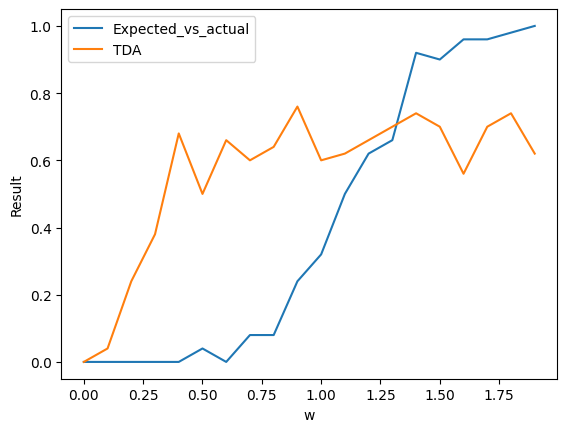

In [72]:
plt.plot(w_range, exp_res, label="Expected_vs_actual")
plt.plot(w_range, TDA_res, label="TDA")

plt.xlabel("w")
plt.ylabel("Result")
plt.legend()
plt.show()

We find that for noisy data, the TDA model significantly outpreforms the expected vs actual model. The expected vs actual model achieves a higher accuracy for sufficiently low noise (high w), but real world data often is often extremely noisy. In practice, it may be beneficial to combine both approaches. (Note that this model is slightly different than that of the paper, so the results are not identical).